In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

DATA_PATH = Path("../data/processed/email_cleaned.csv")

df = pd.read_csv(DATA_PATH)

label
0.0    60650
1.0    48034
Name: count, dtype: int64

Percentage Distribution:
label
0.0    55.8
1.0    44.2
Name: proportion, dtype: float64


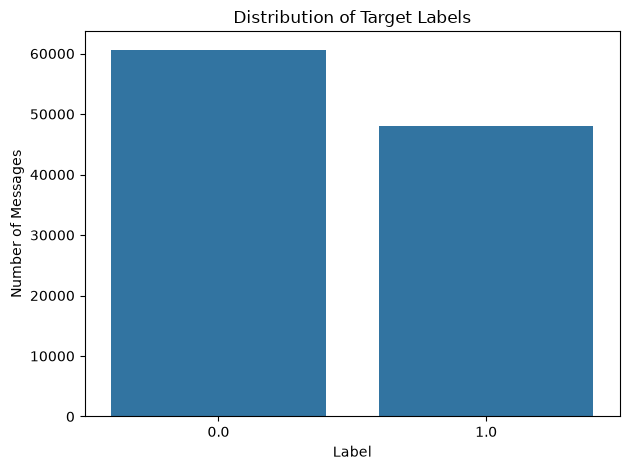

In [2]:
# Check the distribution of target labels
print(df["label"].value_counts())

# Check the percentage distribution
print("\nPercentage Distribution:")
print(
    (df["label"].value_counts(normalize=True) * 100).round(2)
)

# Visualize the distribution
sns.countplot(data=df, x="label")

plt.title("Distribution of Target Labels")
plt.xlabel("Label")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()

In [3]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
sender,0,0.0
sender_domain,0,0.0
receiver,0,0.0
receiver_domain,0,0.0
date,0,0.0
subject,0,0.0
content_types,0,0.0
body,0,0.0
urls,0,0.0
url_count,0,0.0


In [4]:
df.head()

,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,...,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label,has_url
0,d66e9e64b006d6bca649f1c945129c42c43836872b2ead...,enron.com,35c5a9fb9fba3b8737ed7cef2a87e427a73db4fca85f6b...,enron.com,2001-06-29 09:37:04-05:00,[ORGANIZATION] failover plan.,text/plain,"Hi [NAME], \n\nTonight we are rolling out a n...",[NO URL],0.0,...,0.0,0.0,0.0,0.0,False,none,en,trec5,0.0,False
1,0907d5c64598aa2639154ed4e1556be615669e40052a1f...,enron.com,aa2c35499eae5999bf6080453cc719a891da2bb0c3803d...,enron.com,2001-06-29 08:39:30-05:00,RE: Intranet Site,text/plain,"[NAME] r these new?\tIntranet Site\n\n[NAME],\...",http://eastpower.dev.corp.enron.com/summary/pj...,3.0,...,58.0,3.0,3.0,0.0,False,none,en,trec5,0.0,True
2,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,a736837579feb601fbf6c0657d3d93689774afa6491bb9...,enron.com;enron.com,2001-06-29 10:35:17-05:00,FW: [ORGANIZATION] Company information,text/plain,"[NAME]/[NAME],\n\nWe are currently trading und...",[NO URL],0.0,...,0.0,0.0,0.0,0.0,False,none,en,trec5,0.0,False
3,8531d54a169c4af106b9ea2165d4986b8cc10fc0a6bb9b...,enron.com,765a3ec4a67e40118d22de5729b05d090a1b59cb443bf6...,enron.com;enron.com,2001-06-29 10:40:02-05:00,New Master Physical,text/plain,[NAME] and [NAME] -\n\nAttached is a worksheet...,[NO URL],0.0,...,0.0,0.0,0.0,0.0,False,none,en,trec5,0.0,False
4,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,ce418c97ac415706338972e1dbbd99ebb8c617b5c937a3...,enron.com;enron.com;enron.com,2001-06-29 10:48:00-05:00,FW: [ORGANIZATION]/Mirant GISB,text/plain,FYI. Below is a copy of my communication with ...,[NO URL],0.0,...,0.0,0.0,0.0,0.0,False,none,en,trec5,0.0,False


In [29]:
print(df.dtypes)

sender                  str
sender_domain           str
receiver                str
receiver_domain         str
date                    str
subject                 str
content_types           str
body                    str
urls                    str
url_count           float64
url_length_max      float64
url_length_avg      float64
url_subdom_max      float64
url_subdom_avg      float64
attachment_count    float64
has_attachments        bool
attachment_types        str
language                str
source                  str
label               float64
has_url                bool
dtype: object


In [5]:
# analyze the numerical columns
numeric_cols = df.select_dtypes(
    include="number"
).columns.tolist()

display(
    df[numeric_cols].describe().T
)

,count,mean,std,min,25%,50%,75%,max
url_count,108684.0,3.308169,10.507204,0.0,0.0,1.000000,2.0,553.0
url_length_max,108684.0,31.371379,205.157299,0.0,0.0,26.000000,48.0,66647.0
url_length_avg,108684.0,26.691573,203.960722,0.0,0.0,24.500000,43.5,66647.0
url_subdom_max,108684.0,0.659545,0.791753,0.0,0.0,1.000000,1.0,5.0
url_subdom_avg,108684.0,0.585500,0.712160,0.0,0.0,0.215278,1.0,5.0
attachment_count,108684.0,0.020785,0.274446,0.0,0.0,0.000000,0.0,61.0
label,108684.0,0.441960,0.496622,0.0,0.0,0.000000,1.0,1.0


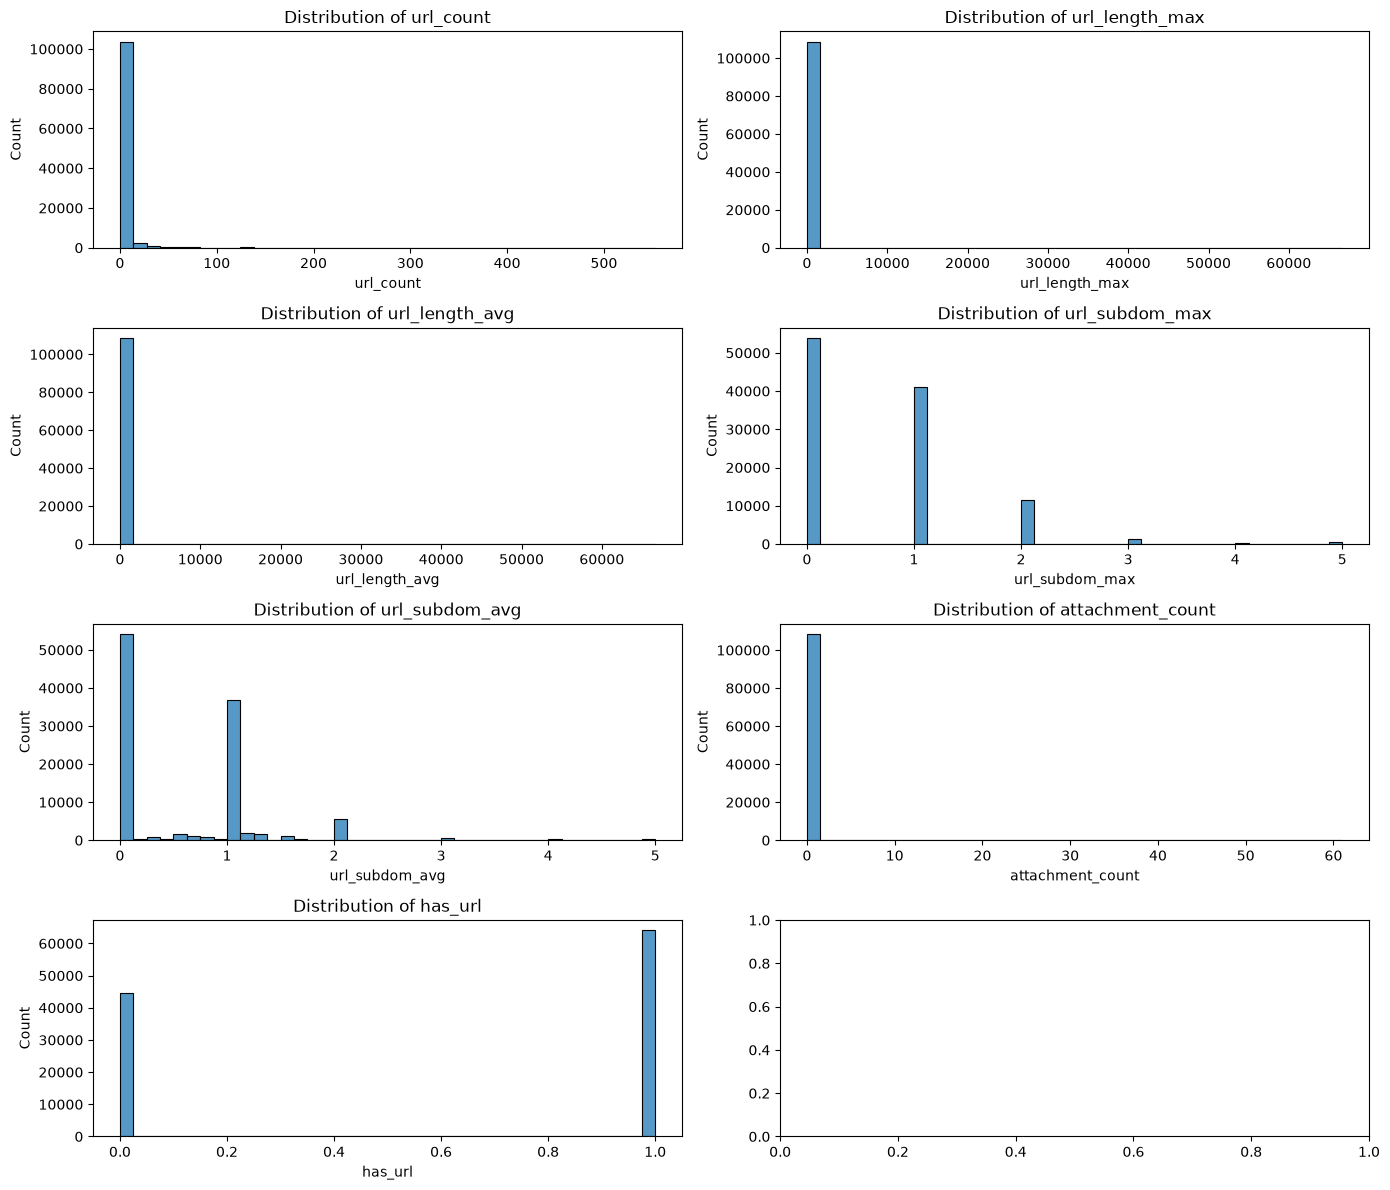

In [11]:
# Visualize the numerical distributions
feature_cols = [
    "url_count",
    "url_length_max",
    "url_length_avg",
    "url_subdom_max",
    "url_subdom_avg",
    "attachment_count",
    'has_url'
]

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(14, 12)
)

axes = axes.flatten()

for ax, col in zip(axes, feature_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=40,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [12]:
feature_cols = [
    "url_count",
    "url_length_max",
    "url_length_avg",
    "url_subdom_max",
    "url_subdom_avg",
    "attachment_count",
    'has_url'
]

display(
    df.groupby("label")[feature_cols]
    .agg(["mean", "median", "std"])
    .T
)

label                          0.0         1.0
url_count        mean     2.725243    4.044198
                 median   0.000000    2.000000
                 std     10.882372    9.964962
url_length_max   mean    24.185243   40.444935
                 median   0.000000   35.000000
                 std     37.609810  305.452587
url_length_avg   mean    19.777015   35.422221
                 median   0.000000   33.000000
                 std     28.600858  304.889669
url_subdom_max   mean     0.509497    0.849003
                 median   0.000000    1.000000
                 std      0.698031    0.859572
url_subdom_avg   mean     0.458920    0.745326
                 median   0.000000    1.000000
                 std      0.615144    0.789936
attachment_count mean     0.034988    0.002852
                 median   0.000000    0.000000
                 std      0.267868    0.281514
has_url          mean     0.407881    0.818462
                 median   0.000000    1.000000
                 std      0.491445    0.385467

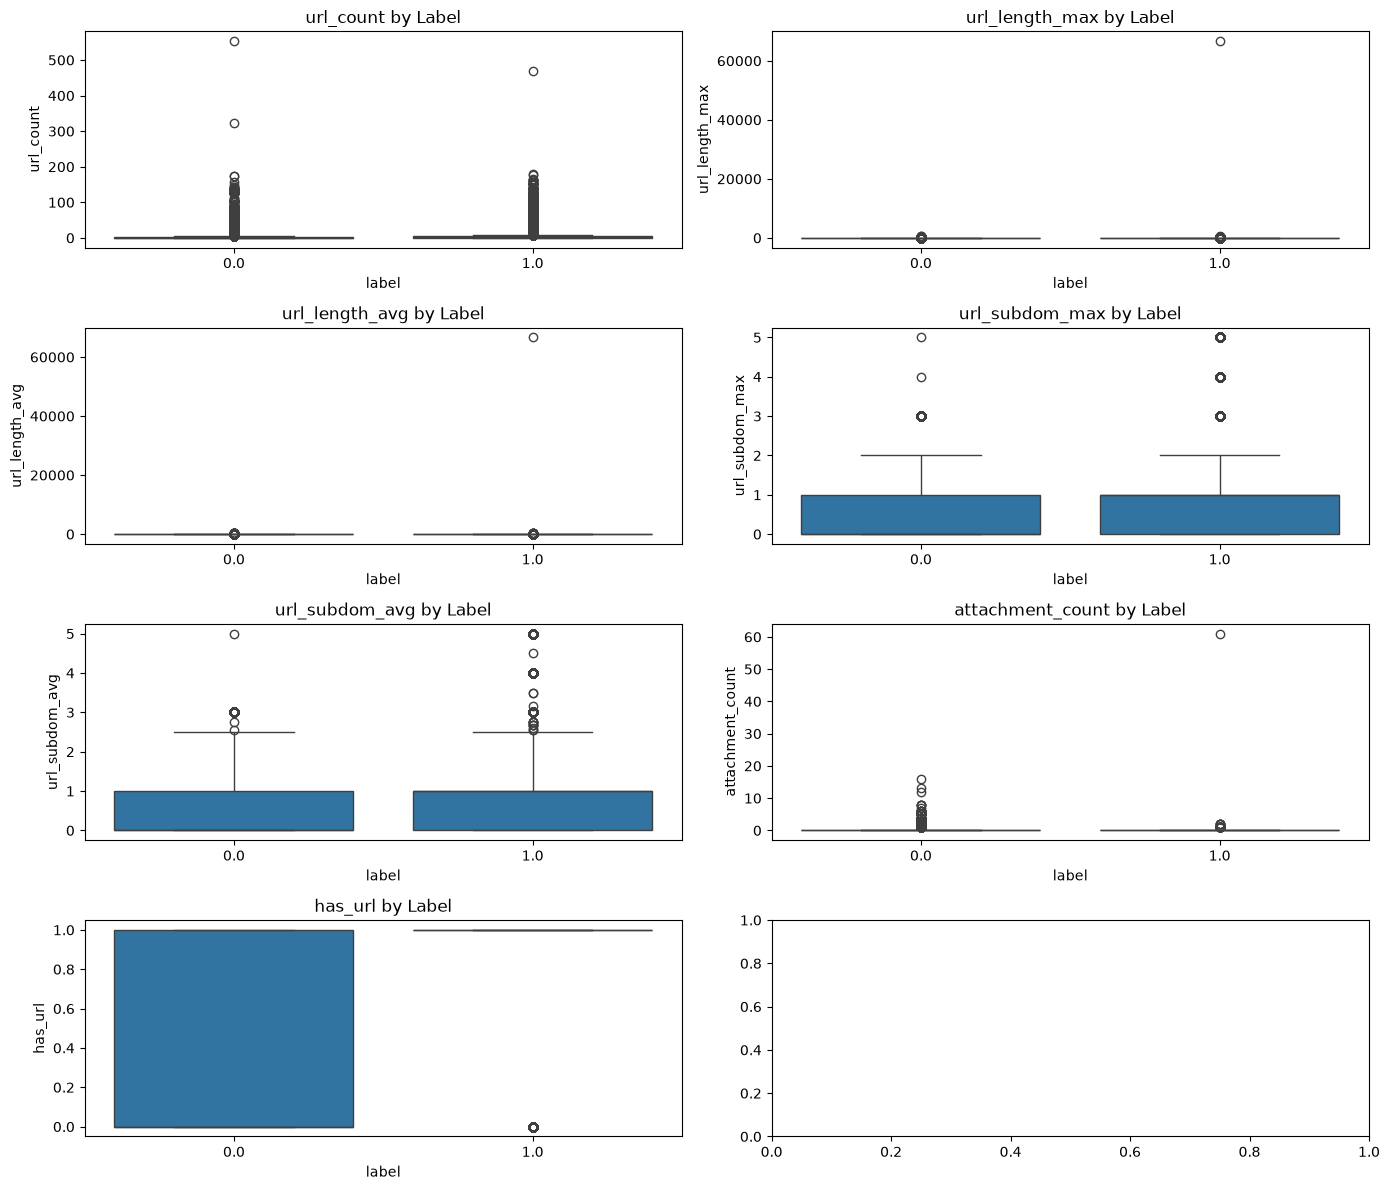

In [14]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(14, 12)
)

axes = axes.flatten()

for ax, col in zip(axes, feature_cols):
    sns.boxplot(
        data=df,
        x="label",
        y=col,
        ax=ax
    )

    ax.set_title(f"{col} by Label")

plt.tight_layout()
plt.show()

In [15]:
url_distribution = pd.crosstab(
    df["label"],
    df["has_url"],
    normalize="index"
) * 100

display(url_distribution.round(2))

has_url,False,True
label,,
0.0,59.21,40.79
1.0,18.15,81.85


In [16]:
attachment_distribution = pd.crosstab(
    df["label"],
    df["has_attachments"],
    normalize="index"
) * 100

display(attachment_distribution.round(2))

has_attachments,False,True
label,,
0.0,97.37,2.63
1.0,99.85,0.15


In [17]:
df["subject_length"] = df["subject"].str.len()

df["body_length"] = df["body"].str.len()

df["body_word_count"] = df["body"].str.split().str.len()

display(
    df[
        [
            "subject_length",
            "body_length",
            "body_word_count"
        ]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
subject_length,108684.0,42.200692,47.372757,1.0,20.0,32.0,47.0,3701.0
body_length,108684.0,1168.111323,1141.704225,1.0,380.0,797.0,1533.0,30574.0
body_word_count,108684.0,171.744893,164.932574,1.0,55.0,121.0,227.0,1199.0


In [18]:
text_features = [
    "subject_length",
    "body_length",
    "body_word_count"
]

display(
    df.groupby("label")[text_features]
    .agg(["mean", "median", "std"])
    .T
)

label                           0.0          1.0
subject_length  mean      36.147040    49.844319
                median    31.000000    32.000000
                std       29.777481    62.076980
body_length     mean    1147.741781  1193.830870
                median   811.000000   783.000000
                std     1080.327980  1214.302612
body_word_count mean     170.944683   172.755278
                median   123.000000   116.000000
                std      157.071470   174.349227

### Correlation Analysis

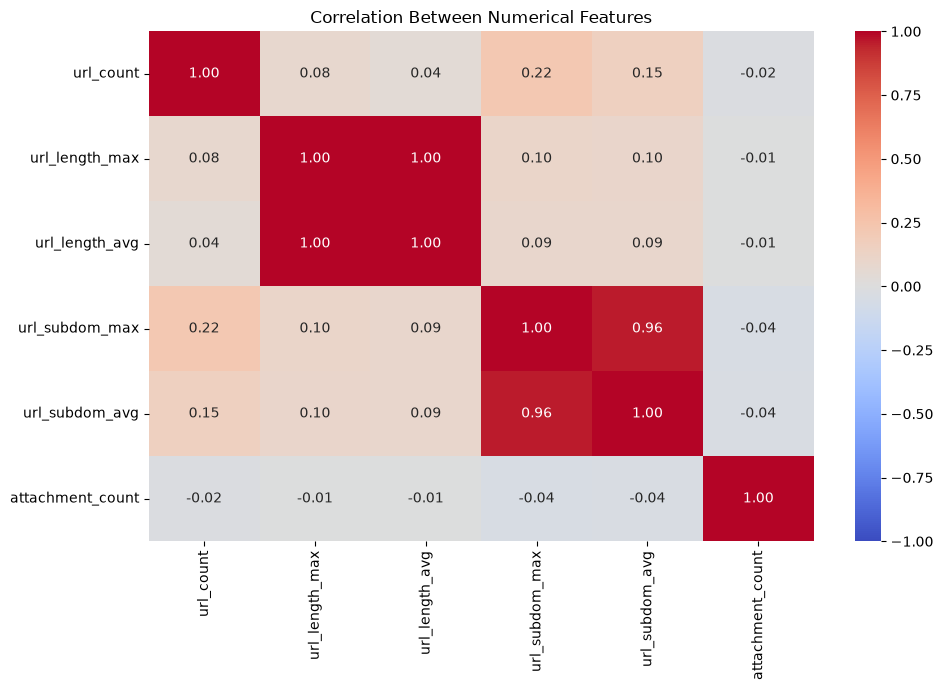

In [19]:
# Select numerical features
numeric_features = [
    "url_count",
    "url_length_max",
    "url_length_avg",
    "url_subdom_max",
    "url_subdom_avg",
    "attachment_count"
]

# Calculate correlation matrix
correlation_matrix = df[numeric_features].corr(method="pearson")

# Visualize correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [22]:
# Select numerical features and the target label
numeric_features = [
    "url_count",
    "url_length_max",
    "url_length_avg",
    "url_subdom_max",
    "url_subdom_avg",
    "attachment_count",
    'has_url'
]

target = "label"

# Calculate correlation with the target
label_correlations = (
    df[numeric_features + [target]]
    .corr(method="pearson")[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

print("Correlation of Features with Label:\n")
display(label_correlations.to_frame(name="Correlation"))

Correlation of Features with Label:



,Correlation
has_url,0.414475
url_subdom_max,0.212953
url_subdom_avg,0.199724
url_count,0.062340
attachment_count,-0.058151
url_length_max,0.039360
url_length_avg,0.038094


In [23]:
# Count emails with and without URLs for each label
url_label_counts = pd.crosstab(
    df["label"],
    df["has_url"],
    margins=True
)

display(url_label_counts)

has_url,False,True,All
label,,,
0.0,35912,24738,60650
1.0,8720,39314,48034
All,44632,64052,108684


In [24]:
# Investigate the categorical columns
categorical_cols = [
    "sender_domain",
    "receiver_domain",
    "language",
    "source",
    "content_types",
    "attachment_types"
]

for col in categorical_cols:
    print(f"\nTop 10 values in {col}:")

    print(
        df[col]
        .value_counts()
        .head(10)
    )


Top 10 values in sender_domain:
sender_domain
enron.com                    21684
gmail.com                     2909
samba.org                     2604
yahoo.com                     2169
hotmail.com                   1542
psy1.psych.arizona.edu        1102
aol.com                        817
mail.cnn.com                   716
broadcast.shareholder.com      689
yahoo.co.kr                    565
Name: count, dtype: int64

Top 10 values in receiver_domain:
receiver_domain
enron.com                 30845
flax9.uwaterloo.ca         9868
plg.uwaterloo.ca           6931
speedy.uwaterloo.ca        6065
media.mit.edu              4675
enron.com;enron.com        2988
psy1.psych.arizona.edu     2664
stat.math.ethz.ch          2468
unknown                    2371
samba.org                  2368
Name: count, dtype: int64

Top 10 values in language:
language
en          82175
en;en       21250
ru            827
ja            602
de            383
es            332
zh            315
fr            303

In [25]:
# Select categorical columns for analysis
analysis_cols = [
    col for col in categorical_cols
    if df[col].nunique() <= 50
]

for col in analysis_cols:

    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    print(f"{'=' * 50}")

    # Counts within each category
    counts = pd.crosstab(
        df[col],
        df["label"]
    )

    display(counts)

    # Percentage distribution within each category
    percentages = pd.crosstab(
        df[col],
        df["label"],
        normalize="index"
    ) * 100

    display(percentages.round(2))


Feature: source


label,0.0,1.0
source,,
trec5,29929,19654
trec6,11208,3797
trec7,19513,24583


label,0.0,1.0
source,,
trec5,60.36,39.64
trec6,74.70,25.30
trec7,44.25,55.75



Feature: content_types


label,0.0,1.0
content_types,,
text/html,1944,13326
text/html;text/html,1,2
text/html;text/plain,0,40
text/html;text/plain;text/plain,0,1
text/plain,54624,16368
text/plain;text/html,2953,18220
text/plain;text/html;text/html;text/plain,8,0
text/plain;text/html;text/plain,98,51
text/plain;text/plain,981,8


label,0.0,1.0
content_types,,
text/html,12.73,87.27
text/html;text/html,33.33,66.67
text/html;text/plain,0.00,100.00
text/html;text/plain;text/plain,0.00,100.00
text/plain,76.94,23.06
text/plain;text/html,13.95,86.05
text/plain;text/html;text/html;text/plain,100.00,0.00
text/plain;text/html;text/plain,65.77,34.23
text/plain;text/plain,99.19,0.81


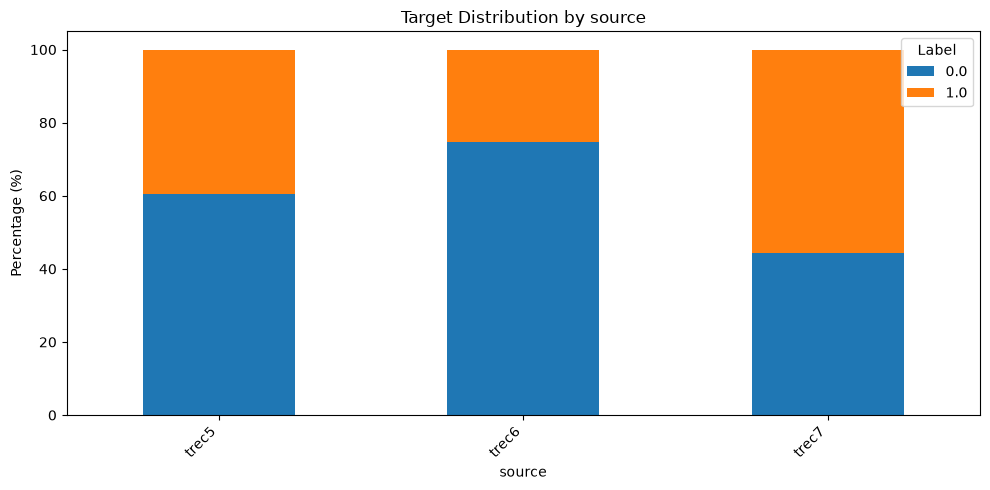

In [26]:
# Choose manageable categorical features
plot_cols = [
    col for col in categorical_cols
    if 2 <= df[col].nunique() <= 15
]

for col in plot_cols:

    percentages = pd.crosstab(
        df[col],
        df["label"],
        normalize="index"
    ) * 100

    ax = percentages.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5)
    )

    ax.set_title(f"Target Distribution by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Percentage (%)")
    ax.legend(title="Label")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


Top domains for sender_domain


label,0.0,1.0
sender_domain,,
aol.com,644,173
broadcast.shareholder.com,689,0
earthlink.net,210,127
enron.com,21660,24
enron.net,448,0
gmail.com,2784,125
hotmail.com,704,838
mail.cnn.com,716,0
media.mit.edu,365,10


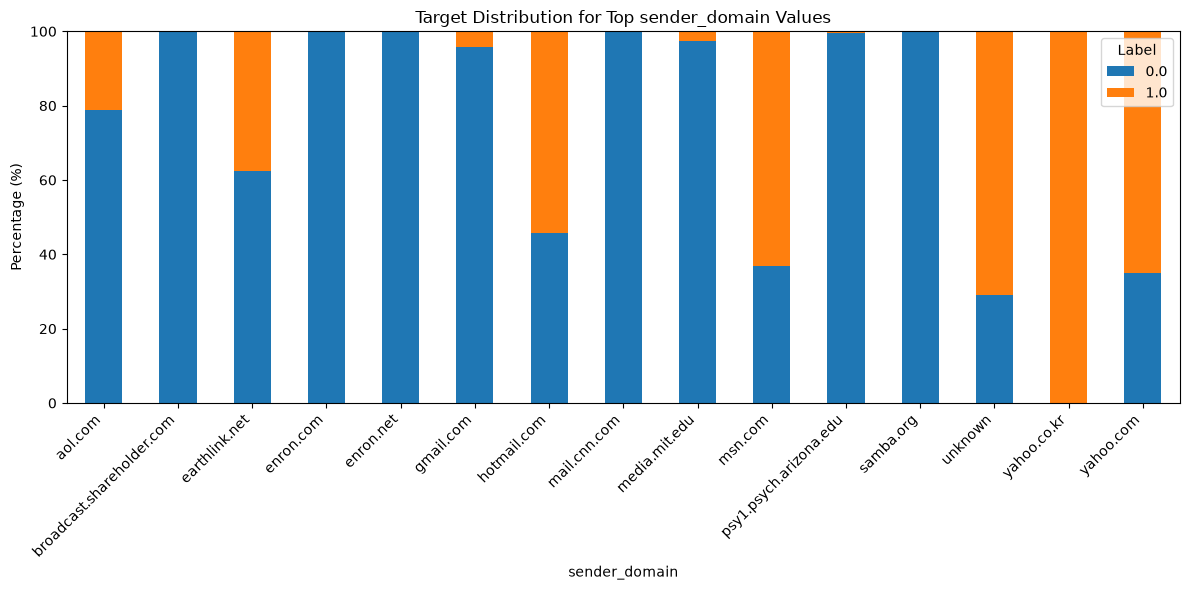


Top domains for receiver_domain


label,0.0,1.0
receiver_domain,,
braille.uwo.ca,1086,0
ect.enron.com,43,1432
enron.com,15723,15122
enron.com;enron.com,2770,218
flax24.uwaterloo.ca,1,1234
flax9.uwaterloo.ca,2139,7729
media.mit.edu,3246,1429
perl.org,1737,1
plg.uwaterloo.ca,0,6931


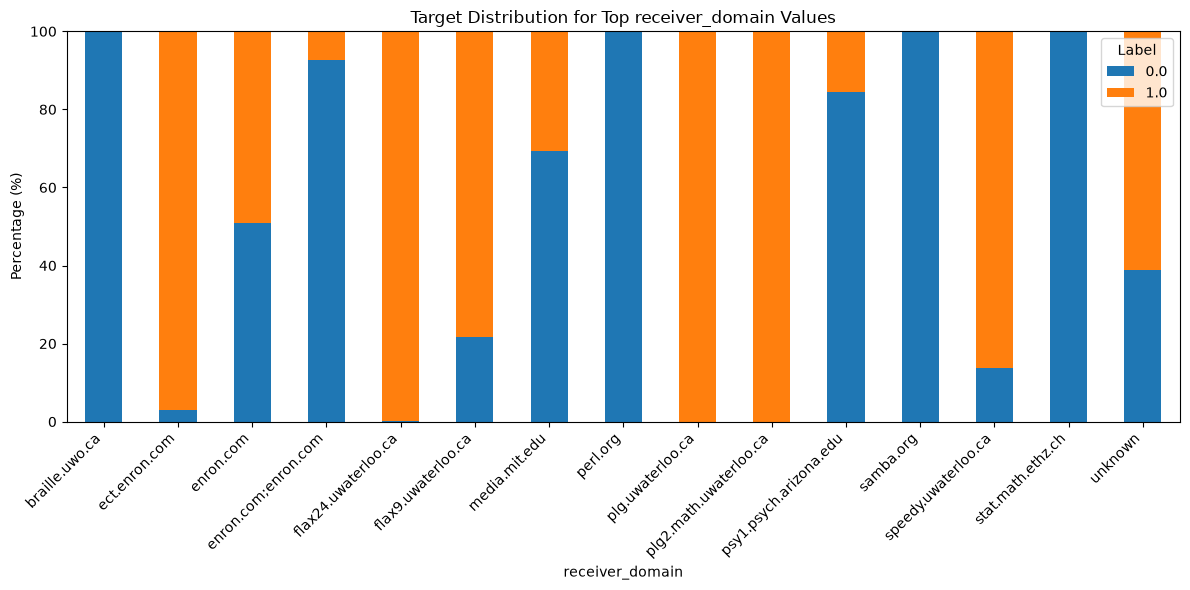

In [27]:
domain_cols = [
    col for col in ["sender_domain", "receiver_domain"]
    if col in df.columns
]

for col in domain_cols:

    top_domains = df[col].value_counts().head(15).index

    domain_df = df[df[col].isin(top_domains)]

    counts = pd.crosstab(
        domain_df[col],
        domain_df["label"]
    )

    percentages = pd.crosstab(
        domain_df[col],
        domain_df["label"],
        normalize="index"
    ) * 100

    print(f"\nTop domains for {col}")
    display(counts)

    ax = percentages.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6)
    )

    ax.set_title(f"Target Distribution for Top {col} Values")
    ax.set_xlabel(col)
    ax.set_ylabel("Percentage (%)")
    ax.legend(title="Label")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [28]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(x, y):

    confusion_matrix = pd.crosstab(x, y)

    chi2 = chi2_contingency(
        confusion_matrix
    )[0]

    n = confusion_matrix.to_numpy().sum()

    r, k = confusion_matrix.shape

    if n == 0 or min(r - 1, k - 1) == 0:
        return np.nan

    return np.sqrt(
        chi2 / (n * min(r - 1, k - 1))
    )

In [29]:
cramers_results = {}

for col in categorical_cols:

    if df[col].nunique() <= 50:

        cramers_results[col] = cramers_v(
            df[col],
            df["label"]
        )

cramers_df = pd.DataFrame({
    "Feature": list(cramers_results.keys()),
    "Cramers_V": list(cramers_results.values())
})

cramers_df = cramers_df.sort_values(
    "Cramers_V",
    ascending=False
)

display(cramers_df)

,Feature,Cramers_V
1,content_types,0.608570
0,source,0.213953
